# Choosing an ensemble with the Pareto search

An ensemble of Spatialize is fixed by a handful of choices, namely how fine the partitions are
(`alpha`), how many of them there are (`n_partitions`) and the parameters of the local interpolator.
This tutorial chooses them on the encoder–decoder Pareto frontier, the way every other tutorial of this
gallery chooses them, on fields whose truth is known, so that each choice can be checked.

## What you will learn

- What the two errors of an ensemble are, and why cross-validation sees only their sum.
- How `esi_pareto_hparams_search` measures each of them and returns the frontier between them.
- How to read the frontier with the strategies `"min_decoder"`, `"knee"` and `"min_epsilon"`, and
  with a level `tau` of encoder error.
- Which reading holds up against the truth, with the adaptive decoder and with plain IDW.

It answers one question. *Which granularity, number of partitions and decoder parameters should an
ensemble use for these data?*

## The idea

Spatialize predicts in two steps. A random partition of the domain, the **encoder**, puts each location
in a cell. A local interpolator, the **decoder**, predicts inside each cell from the data that fall in
it. The theory behind Spatialize splits the error of the prediction exactly into two parts, one for
each step.

- The **encoder error** measures what the cell forgets about the location. The field may vary inside
  a cell, while every location of the cell is predicted from the same data. It depends on the
  partition alone. Finer cells are more homogeneous, so it falls as `alpha` grows.
- The **decoder error** is how well the interpolator fits the values inside a cell. Finer cells hold
  fewer data, so it rises as `alpha` grows.

Cross-validation predicts each datum from the others, so its error estimates the sum of the two, plus
the noise no model removes. No decoder lowers the encoder part, which is why a search that minimises
the cross-validation error alone picks the best decoder for each partition while the encoder error of
the partition stays hidden.

The Pareto search therefore measures the encoder error on its own. Each datum gets the law of the
values around it, here those of its 16 nearest data, fitted once for the whole search. For each
partition, the encoder error `ε̂` is the largest divergence between the laws of two data that share a
cell, the neighbours the partition treats as alike. The ensemble's `ε̂` is its mean over the
partitions. A configuration is on the **frontier** when no other has both errors at most as large.
The frontier need not be convex, so it is read with a constraint, the best decoder error under a level
`τ` of encoder error, and not with a weighted sum of the two errors. (See the chapter on the total
approximation error in the book behind Spatialize, and the theory page
[Error and the choice of a model](https://spatialize.readthedocs.io/en/latest/theory/error.html) of its
documentation.)

## Step by step

### The session

At fine granularities some cells hold no datum. By default (`empty_cells="nan"`) a location in such a
cell gets no member from that partition, so in cross-validation a datum alone in its cell has no
prediction and drops out of the score. The score then rests on the data that keep neighbours, the
easier ones, which favours partitions too fine for the data. The session setting
`empty_cells="coarsen"` predicts such a location from the nearest coarser cell that holds data, so
every datum takes part in the score. Every search and estimate of this tutorial uses it.

In [1]:
import spatialize
spatialize.session.set(empty_cells="coarsen")

### The data

The field is one of the anisotropic Gaussian simulations bundled with Spatialize, on a 200 × 200
grid, with 400 data (1 % of the grid) as samples. Since the whole grid is known, the choices made from
the 400 data can be checked against the truth at the end, a luxury real data never give.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spatialize.data import load_simulated_anisotropic_data
from spatialize.evaluation import MAE
from spatialize.gs.esi import esi_hparams_search, esi_pareto_hparams_search, esi_nongriddata
import spatialize.gs.esi.scorefunction as sf

(samples, _), _, _, grid = load_simulated_anisotropic_data()
realisation = "sim1"
points, values = samples[["x", "y"]].values, samples[realisation].values
xi, truth = grid[["x", "y"]].values, grid[realisation].values
print(f"{len(points)} data, {len(xi)} grid nodes, values from {values.min():.2f} to {values.max():.2f}")

400 data, 40000 grid nodes, values from -2.17 to 2.67


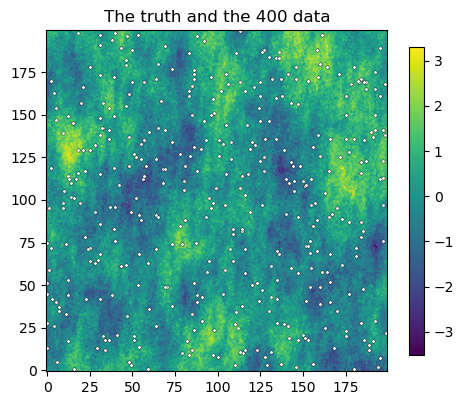

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(truth.reshape(200, 200).T, origin="lower", cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=6, c="white", edgecolors="black", linewidths=0.3)
ax.set_title("The truth and the 400 data")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

The field varies at a scale close to the spacing of the data, so 400 data catch its large patches of
high and low values but not the detail between them. Its correlation is longer in one direction than
in the other, which a decoder with a single isotropic weighting cannot follow.

### The decoder

The decoder is the adaptive IDW (`local_interpolator="adaptiveidw"`), the best of Spatialize on such
fields. In every cell it fits its own exponent and its own anisotropy to the data of the cell, so it
follows the direction of the field cell by cell and leaves no global parameter to search. The search
then runs over the encoder alone, the granularity `alpha` and the number of partitions.

### The Pareto search

`esi_pareto_hparams_search` computes both errors for every configuration. The decoder error is the
leave-one-out error (`k="loo"`, each datum predicted from the other 399), scored by the mean absolute
error (`sf.mae`), the error of the map.

In [4]:
alphas = [0.5, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98]
pareto = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw",
                                   n_partitions=[50, 100, 200], alpha=alphas,
                                   k="loo", scoring=sf.mae, seed=0)
pareto

======================================================================================
spatialize · ESI Pareto search                                  mondrian · adaptiveidw
======================================================================================
Search                                      Best (min decoder error)
  configurations                        21    alpha                               0.95
  on the frontier                        4    metric                               mae
  partition                       mondrian    n_partitions                         100
  decoder                      adaptiveidw
--------------------------------------------------------------------------------------
Frontier, by encoder error
      alpha  n_partitions  encoder ε̂  decoder error
  --------------------------------------------------
  #1   0.98            50       2.518         0.4278
  #2   0.98           100       2.739         0.4236
  #3   0.95            50       7.691         0.3848
  #4   0.95           100       8.267         0.3832
--------------------------------------------------------------------------------------
best_result(strategy) · best_for_tau(tau) · frontier · all_results
======================================================================================

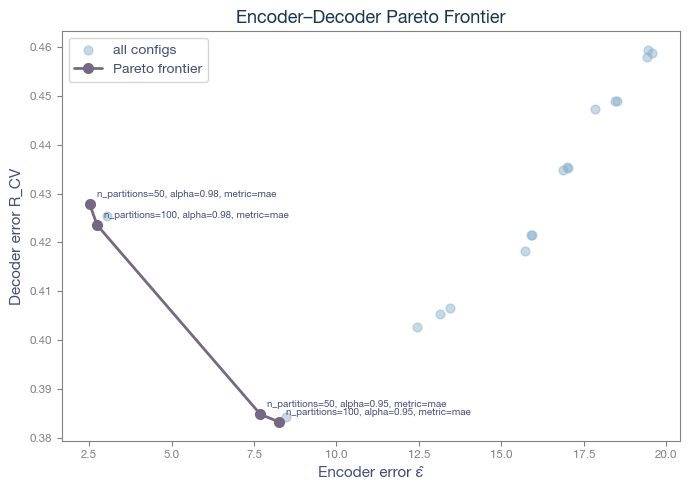

<Axes: title={'center': 'Encoder–Decoder Pareto Frontier'}, xlabel='Encoder error ε̂', ylabel='Decoder error R_CV'>

In [5]:
pareto.plot(annotate=True)

Read the plot from right to left. Coarse partitions (small `alpha`) sit on the right, since their
cells pool places where the field differs, which makes the encoder error large. Moving left, the cells
shrink while the encoder error falls. The decoder error first falls too, then rises at the finest
granularity, where the cells hold too few data to fit a decoder. The points joined by the line are the
frontier, the configurations no other beats on both errors at once.

In [6]:
table = pd.DataFrame([{**r["params"], "encoder ε̂": r["epsilon"], "decoder error": r["decoder_error"]}
                      for r in pareto.all_results])
table.pivot(index="alpha", columns="n_partitions", values="encoder ε̂").round(2)

n_partitions,50,100,200
alpha,,,
0.50,19.41,19.56,19.45
0.70,17.82,18.51,18.44
0.80,16.85,17.00,17.01
0.85,15.71,15.93,15.89
0.90,12.44,13.13,13.45
0.95,7.69,8.27,8.47
0.98,2.52,2.74,3.05


The encoder error depends on the granularity and hardly on the number of partitions. `ε̂` is a mean
over the partitions, so more partitions estimate it better without changing it. The number of
partitions is a question of cost and of the spread of the ensemble, treated in its own tutorial.

### Reading the frontier

`best_result` reads the frontier with a strategy, and `best_for_tau` picks the best decoder error
under a level of encoder error. Each returns the configuration as a dictionary that the estimation
functions accept as `best_params_found`.

In [7]:
choices = {s: pareto.best_result(strategy=s) for s in ("min_decoder", "knee", "min_epsilon")}
tau = 5.0
choices[f"best under τ = {tau}"] = pareto.best_for_tau(tau=tau)
pd.DataFrame([{"reading": name, "alpha": c["alpha"], "n_partitions": int(c["n_partitions"])}
              for name, c in choices.items()]).set_index("reading")

,alpha,n_partitions
reading,,
min_decoder,0.95,100
knee,0.95,50
min_epsilon,0.98,50
best under τ = 5.0,0.98,100


- `"min_decoder"` takes the frontier point of lowest decoder error. Trusting the partition, it makes
  the choice cross-validation alone would make among the frontier.
- `"knee"` takes the point where lowering one error starts to cost much more of the other.
- `"min_epsilon"` takes the point of lowest encoder error, the finest partition the frontier keeps.
- `best_for_tau` makes the encoder error a requirement, taking the lowest decoder error below `τ`.

### Checking against the truth

On this simulation the truth is known, so each granularity can be judged by its error on the whole
grid. The estimation uses the 400 data and 100 partitions, as a user would after the search.

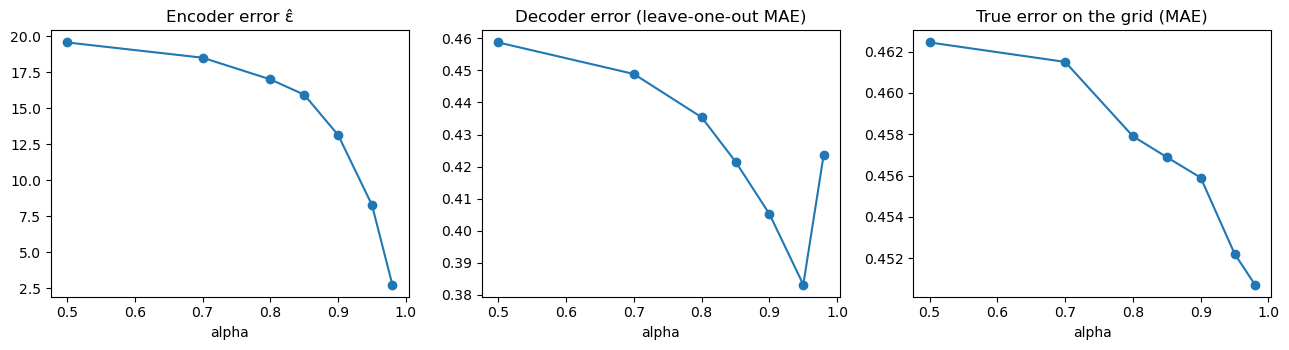

,0.50,0.70,0.80,0.85,0.90,0.95,0.98
true MAE,0.4624,0.4615,0.4579,0.4569,0.4559,0.4522,0.4507


In [8]:
true_error = {}
for a in alphas:
    estimate = esi_nongriddata(points, values, xi, local_interpolator="adaptiveidw",
                               n_partitions=100, alpha=a, seed=0)
    true_error[a] = MAE(truth, estimate.estimation())

at_100 = table[table["n_partitions"] == 100].set_index("alpha")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(alphas, at_100["encoder ε̂"], "o-"); axes[0].set_title("Encoder error ε̂")
axes[1].plot(alphas, at_100["decoder error"], "o-"); axes[1].set_title("Decoder error (leave-one-out MAE)")
axes[2].plot(alphas, list(true_error.values()), "o-"); axes[2].set_title("True error on the grid (MAE)")
for ax in axes:
    ax.set_xlabel("alpha")
plt.tight_layout()
plt.show()
pd.Series(true_error, name="true MAE").round(4).to_frame().T

The leave-one-out error is lower than the true error at every granularity. The adaptive decoder fits
its exponent and anisotropy on the data of each cell, the held-out datum's neighbours included, so its
cross-validation is optimistic. The decoder error turns up at the finest granularity while the true
error keeps falling, since the cells left empty are predicted from coarser ones. The encoder error
follows the truth to the end.

In [9]:
pd.DataFrame([{"reading": name, "alpha": c["alpha"], "true MAE": round(true_error[c["alpha"]], 4)}
              for name, c in choices.items()]).set_index("reading")

,alpha,true MAE
reading,,
min_decoder,0.95,0.4522
knee,0.95,0.4522
min_epsilon,0.98,0.4507
best under τ = 5.0,0.98,0.4507


### The chosen ensemble

The readings differ here by a third of a per cent of the error. The knee, a balanced reading of the
frontier, is the one this gallery uses. The estimate uses it with 200 partitions, since
`best_params_found` passes every parameter except the number of partitions, which is given at the
call. A search can thus run with few partitions while the estimate uses many.

alpha = 0.95, true MAE = 0.4518


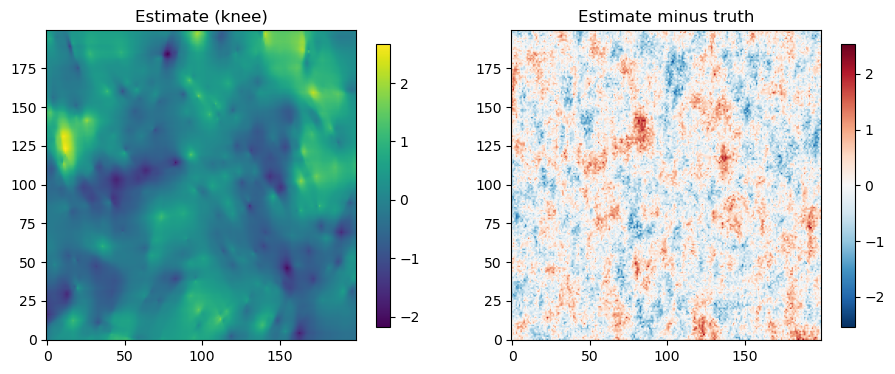

In [10]:
best = pareto.best_result(strategy="knee")
result = esi_nongriddata(points, values, xi, n_partitions=200, best_params_found=best, seed=0)
estimate = result.estimation()
print(f"alpha = {best['alpha']}, true MAE = {MAE(truth, estimate):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
lim = np.abs(estimate - truth).max()
for ax, field, title, cmap, bounds in ((axes[0], estimate, "Estimate (knee)", "viridis", (None, None)),
                                       (axes[1], estimate - truth, "Estimate minus truth", "RdBu_r", (-lim, lim))):
    im = ax.imshow(field.reshape(200, 200).T, origin="lower", cmap=cmap, vmin=bounds[0], vmax=bounds[1])
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

The errors form patches the size of the field's own features, the detail between the data that no
choice of parameters recovers from 400 data. The choice of the ensemble moves the error by a few per
cent, while the data set its floor.

### The same readings with plain IDW

Plain IDW, with one exponent for the whole domain, is the other decoder to check. A fair test needs a
field without a preferred direction, which a single isotropic weighting can follow, so the comparison
uses an isotropic Gaussian field with an exponential covariance of range 8, simulated on a 64 × 64
grid, with 300 of its nodes as data.

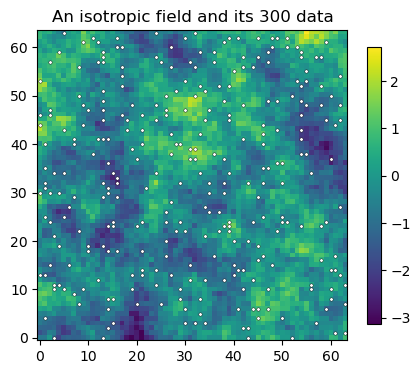

In [11]:
m = 64
nodes = np.stack(np.meshgrid(np.arange(m), np.arange(m), indexing="ij"), -1).reshape(-1, 2).astype(float)
distance = np.sqrt(((nodes[:, None, :] - nodes[None, :, :]) ** 2).sum(-1))
cholesky = np.linalg.cholesky(np.exp(-distance / 8.0) + 1e-8 * np.eye(len(nodes)))

def isotropic_field(seed):
    rng = np.random.default_rng(seed)
    field = cholesky @ rng.standard_normal(len(nodes))
    picked = rng.choice(len(nodes), 300, replace=False)
    return field, nodes[picked], field[picked]

iso_truth, iso_points, iso_values = isotropic_field(101)
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(iso_truth.reshape(m, m).T, origin="lower", cmap="viridis")
ax.scatter(iso_points[:, 0], iso_points[:, 1], s=6, c="white", edgecolors="black", linewidths=0.3)
ax.set_title("An isotropic field and its 300 data")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Cross-validation alone (`esi_hparams_search`) and the Pareto search run on the same grid of
granularities, with IDW of exponent 2, before the truth judges both. The grid reaches 0.995, where most
cells hold one datum or none.

In [12]:
iso_alphas = [0.9, 0.95, 0.98, 0.99, 0.995]

def compare(field, pts, vals):
    cv = esi_hparams_search(pts, vals, nodes, griddata=False, local_interpolator="idw", n_partitions=[100],
                            alpha=iso_alphas, exponent=[2.0], k="loo", scoring=sf.mae, seed=0)
    front = esi_pareto_hparams_search(pts, vals, local_interpolator="idw", n_partitions=[100],
                                      alpha=iso_alphas, exponent=[2.0], k="loo", scoring=sf.mae, seed=0)
    truth_error = {a: MAE(field, esi_nongriddata(pts, vals, nodes, local_interpolator="idw", n_partitions=100,
                                                 alpha=a, exponent=2.0, seed=0).estimation())
                   for a in iso_alphas}
    picks = {"cross-validation alone": cv.best_result()["alpha"],
             "knee": front.best_result(strategy="knee")["alpha"],
             "min_epsilon": front.best_result(strategy="min_epsilon")["alpha"]}
    return picks, truth_error

with spatialize.session.override(progress=False):
    picks, iso_true = compare(iso_truth, iso_points, iso_values)
print(pd.Series(iso_true, name="true MAE").round(4).to_frame().T)
print(f"best granularity {min(iso_true, key=iso_true.get)}")
print(pd.Series(picks, name="alpha picked").to_frame())

           0.900   0.950   0.980   0.990   0.995
true MAE  0.4084  0.4015  0.3972  0.3993  0.3986
best granularity 0.98
                        alpha picked
cross-validation alone         0.995
knee                           0.995
min_epsilon                    0.995


One realisation proves little, so the same comparison runs on ten. For each reading it counts how
often it lands on the granularity of lowest true error, and how much larger its true error is than
the best one, on average. The progress bars are switched off for the loop.

In [13]:
readings = ("cross-validation alone", "knee", "min_epsilon")
hits, excess = {r: 0 for r in readings}, {r: [] for r in readings}
with spatialize.session.override(progress=False):
    for seed in range(100, 110):
        field, pts, vals = isotropic_field(seed)
        picks, errors = compare(field, pts, vals)
        lowest = min(errors.values())
        for name, a in picks.items():
            hits[name] += errors[a] == lowest
            excess[name].append(100 * (errors[a] / lowest - 1))
pd.DataFrame({"best granularity found, out of 10": hits,
              "mean excess error (%)": {r: round(np.mean(e), 2) for r, e in excess.items()},
              "largest excess error (%)": {r: round(np.max(e), 2) for r, e in excess.items()}})

,"best granularity found, out of 10",mean excess error (%),largest excess error (%)
cross-validation alone,4,0.39,1.23
knee,5,0.27,0.85
min_epsilon,4,0.32,1.09


With the empty cells coarsened, the finest granularities lose little, so the three readings all land
close to the best one. On average their true error exceeds the lowest by 0.27 % for the knee, 0.32 %
for the lowest encoder error and 0.39 % for cross-validation alone, never by more than 1.3 %. The knee
finds the best granularity most often and misses it by the least, by margins too small to matter for
a single map. On these fields the data set the error, while the frontier tells which granularities
are reasonable.

On the realisation shown above, the knee's ensemble gives the following map.

alpha = 0.995, true MAE = 0.3968


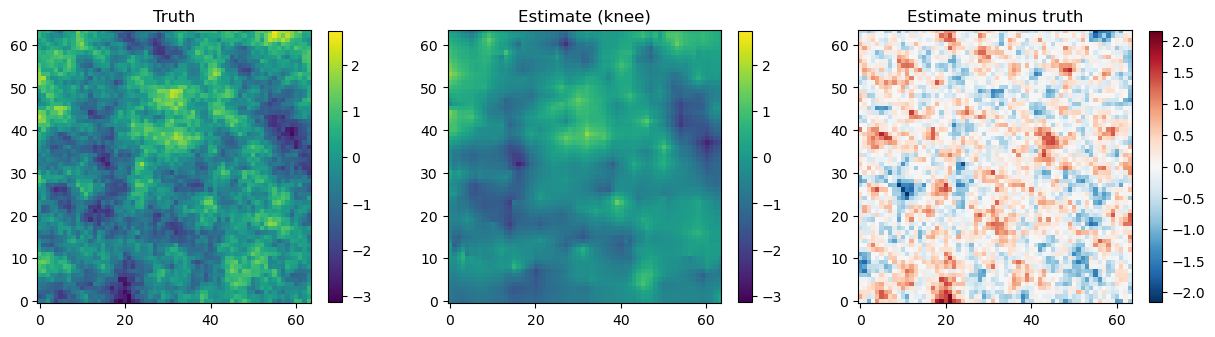

In [14]:
iso_best = esi_pareto_hparams_search(iso_points, iso_values, local_interpolator="idw", n_partitions=[100],
                                     alpha=iso_alphas, exponent=[2.0], k="loo", scoring=sf.mae,
                                     seed=0).best_result(strategy="knee")
iso_estimate = esi_nongriddata(iso_points, iso_values, nodes, n_partitions=200, best_params_found=iso_best,
                               seed=0).estimation()
print(f"alpha = {iso_best['alpha']}, true MAE = {MAE(iso_truth, iso_estimate):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
lim = np.abs(iso_estimate - iso_truth).max()
for ax, field, title, cmap, bounds in ((axes[0], iso_truth, "Truth", "viridis", (iso_truth.min(), iso_truth.max())),
                                       (axes[1], iso_estimate, "Estimate (knee)", "viridis", (iso_truth.min(), iso_truth.max())),
                                       (axes[2], iso_estimate - iso_truth, "Estimate minus truth", "RdBu_r", (-lim, lim))):
    im = ax.imshow(field.reshape(m, m).T, origin="lower", cmap=cmap, vmin=bounds[0], vmax=bounds[1])
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## What can go wrong

- **An optimistic cross-validation.** Decoders that fit themselves inside each cell (the adaptive and
  sharpened IDW) give leave-one-out errors below the true error. Compare their configurations with
  each other, not their cross-validation errors with those of other decoders.
- **A score that rewards spread.** With an averaging decoder such as IDW, the members of the ensemble
  are closer together than the values in a cell. The negative log-likelihood (`sf.neg_log_likelihood`,
  the default score) then rewards any configuration that adds spread, whatever the reason. Score with
  the absolute error, as here, for the map, or use a drawing decoder of the same weights
  (`local_interpolator="wdraw_idw"`) for the law.
- **A frontier of one point.** When both errors fall over the whole grid of `alpha`, one configuration
  beats all the others, leaving a frontier of one point. The grid then stops before the trade-off
  begins, so extend it towards 1.
- **Data left out of the score.** Without `empty_cells="coarsen"` (or `"mark"`), the data alone in
  their cells drop out of the cross-validation score, which then favours partitions too fine for the
  data. The search warns when the share left out passes the session's `max_left_out`.
- **Reading `n_partitions` from the frontier.** The encoder error does not depend on it, so its place on
  the frontier says little. Choose it by cost and by the stability of the ensemble.

## Try it yourself

1. Change `realisation` to `"sim2"`, …, `"sim10"` and see where the knee lands against the truth.
2. Use the denser sample (`load_simulated_anisotropic_data()[1]`, 2 000 data). The trade-off moves to
   finer granularities, since smaller cells still hold data.
3. Run the anisotropic field with plain IDW and look at the map. Its round bull's-eyes around the
   data, where the field is elongated, show why the adaptive decoder is the one to use there.
4. Give your own laws to the encoder error with `reference_laws` (a matrix of draws per datum, or a
   function), for instance from a model of the measurement error.

## Next

- *Uncertainty at a location*, to read the ensemble chosen here as a law at every location.
- *How many partitions?*, for the number of partitions the frontier leaves open.
- *The granularity `alpha` and the range of the field*, for what `alpha` means in distance.
- *The decoders*, for the adaptive IDW and the other local interpolators.
- The documentation's [Error and the choice of a model](https://spatialize.readthedocs.io/en/latest/theory/error.html)
  (theory) and [Choosing a model](https://spatialize.readthedocs.io/en/latest/reference/selection.html)
  (reference).